In [ ]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [ ]:
training = '/content/drive/MyDrive/Dataset/primer/training'
test = '/content/drive/MyDrive/Dataset/primer/test'

In [ ]:
#PERCOBAAN 1 (LAPORAN)
import cv2
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Dense, Dropout, Flatten
from keras.optimizers import Adam
from keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
import numpy as np
from keras.regularizers import l2
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, f1_score, roc_curve, auc
import seaborn as sns
from keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

In [ ]:
#PERCOBAAN 1 (LAPORAN)
train_data_gen = ImageDataGenerator(rescale=1./255)
validation_data_gen = ImageDataGenerator(rescale=1./255)

train_generator = train_data_gen.flow_from_directory(
    training,
    target_size=(48, 48),
    batch_size=32,
    color_mode="grayscale",
    class_mode='categorical',
    shuffle=True
)

validation_generator = validation_data_gen.flow_from_directory(
    test,
    target_size=(48, 48),
    batch_size=32,
    color_mode="grayscale",
    class_mode='categorical',
    shuffle=False
)

Found 800 images belonging to 2 classes.
Found 200 images belonging to 2 classes.


In [ ]:
# #PERCOBAAN 1 (LAPORAN)
# emotion_model = Sequential()

# #layer 1
# emotion_model.add(Conv2D(32, kernel_size=(3, 3),padding='same',activation='relu',input_shape=(48, 48, 1)))
# emotion_model.add(Conv2D(64, kernel_size=(3, 3),padding='same', activation='relu'))
# emotion_model.add(MaxPooling2D(pool_size=(2, 2)))
# emotion_model.add(Dropout(0.2))

# #layer 2
# emotion_model.add(Conv2D(128, kernel_size=(3, 3),padding='same', activation='relu'))
# emotion_model.add(MaxPooling2D(pool_size=(2, 2)))
# emotion_model.add(Dropout(0.2))

# #layer 3
# emotion_model.add(Conv2D(128, kernel_size=(3, 3),padding='same', activation='relu'))
# emotion_model.add(MaxPooling2D(pool_size=(2, 2)))
# emotion_model.add(Dropout(0.2))

# emotion_model.add(Flatten())
# emotion_model.add(Dense(1024, activation='relu'))
# emotion_model.add(Dropout(0.2))
# emotion_model.add(Dense(2, activation='softmax'))

#PERCOBAAN 2 (LAPORAN)
emotion_model = Sequential()

#layer 1
emotion_model.add(Conv2D(32, kernel_size=(3, 3),padding='same',activation='relu',input_shape=(48, 48, 1)))
emotion_model.add(Conv2D(64, kernel_size=(3, 3),padding='same', activation='relu'))
emotion_model.add(MaxPooling2D(pool_size=(2, 2)))
emotion_model.add(Dropout(0.2))

#layer 2
emotion_model.add(Conv2D(128, kernel_size=(3, 3),padding='same', activation='relu'))
emotion_model.add(MaxPooling2D(pool_size=(2, 2)))
emotion_model.add(Dropout(0.2))

#layer 3
emotion_model.add(Conv2D(128, kernel_size=(3, 3),padding='same', activation='relu'))
emotion_model.add(MaxPooling2D(pool_size=(2, 2)))
emotion_model.add(Dropout(0.2))

emotion_model.add(Flatten())
emotion_model.add(Dense(1024, activation='relu'))
emotion_model.add(Dropout(0.2))
emotion_model.add(Dense(2, activation='softmax'))

In [ ]:
#PERCOBAAN 1 (LAPORAN)
cv2.ocl.setUseOpenCL(False)

In [ ]:
#PERCOBAAN 1 (LAPORAN)
emotion_model.compile(
    loss='categorical_crossentropy',
    optimizer = Adam(learning_rate=0.001),
    metrics=['accuracy'])

In [ ]:
#PERCOBAAN 1 (LAPORAN)
checkpoint = ModelCheckpoint('model_weights.h5', monitor='accuracy', verbose=1, save_best_only=True)

ealy_stopping = EarlyStopping(monitor='accuracy',
                              min_delta=0,
                              patience=3,
                              verbose=1,
                              restore_best_weights=True)

reduce_learningrate = ReduceLROnPlateau(monitor='accuracy',
                                        factor=0.2,
                                        patience=3,
                                        verbose=1,
                                        min_delta=0.0001)
callbacks_list = [checkpoint]

In [ ]:
# #PERCOBAAN 1 (LAPORAN)
# emotion_model_info = emotion_model.fit(
#         train_generator,
#         steps_per_epoch=800 // 64,
#         epochs=60,
#         validation_data=validation_generator,
#         validation_steps=200 // 64,
#         callbacks=callbacks_list)

#PERCOBAAN 2 (LAPORAN)
emotion_model_info = emotion_model.fit(
        train_generator,
        steps_per_epoch=800 // 32,
        epochs=60,
        validation_data=validation_generator,
        validation_steps=200 // 32,
        callbacks=callbacks_list)

Epoch 1/60
25/25 [==============================] - ETA: 0s - loss: 0.7096 - accuracy: 0.5213
Epoch 1: accuracy improved from -inf to 0.52125, saving model to model_weights.h5
25/25 [==============================] - 254s 10s/step - loss: 0.7096 - accuracy: 0.5213 - val_loss: 0.6950 - val_accuracy: 0.4792
Epoch 2/60


/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


25/25 [==============================] - ETA: 0s - loss: 0.6943 - accuracy: 0.5113
Epoch 2: accuracy did not improve from 0.52125
25/25 [==============================] - 18s 717ms/step - loss: 0.6943 - accuracy: 0.5113 - val_loss: 0.6931 - val_accuracy: 0.4792
Epoch 3/60
25/25 [==============================] - ETA: 0s - loss: 0.6935 - accuracy: 0.4950
Epoch 3: accuracy did not improve from 0.52125
25/25 [==============================] - 20s 781ms/step - loss: 0.6935 - accuracy: 0.4950 - val_loss: 0.6910 - val_accuracy: 0.5208
Epoch 4/60
25/25 [==============================] - ETA: 0s - loss: 0.6915 - accuracy: 0.5350
Epoch 4: accuracy improved from 0.52125 to 0.53500, saving model to model_weights.h5
25/25 [==============================] - 18s 720ms/step - loss: 0.6915 - accuracy: 0.5350 - val_loss: 0.6827 - val_accuracy: 0.5573
Epoch 5/60
25/25 [==============================] - ETA: 0s - loss: 0.6752 - accuracy: 0.5550
Epoch 5: accuracy improved from 0.53500 to 0.55500, saving m

In [ ]:
#PERCOBAAN 1 (LAPORAN)
emotion_model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 48, 48, 32)        320       
                                                                 
 conv2d_1 (Conv2D)           (None, 48, 48, 64)        18496     
                                                                 
 max_pooling2d (MaxPooling2  (None, 24, 24, 64)        0         
 D)                                                              
                                                                 
 dropout (Dropout)           (None, 24, 24, 64)        0         
                                                                 
 conv2d_2 (Conv2D)           (None, 24, 24, 128)       73856     
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 12, 12, 128)       0         
 g2D)                                                   

In [ ]:
#PERCOBAAN 1 (LAPORAN)
model_json = emotion_model.to_json()
with open("emotion_model.json", "w") as json_file:
    json_file.write(model_json)

emotion_model.save_weights('emotion_model.h5')

In [ ]:
#PERCOBAAN 1 (LAPORAN)
# Make predictions on the validation set
validation_steps = len(validation_generator)
validation_result = emotion_model.evaluate(validation_generator, steps=validation_steps)

# Get true labels and predicted labels
validation_generator.reset()
y_true = validation_generator.classes
y_pred = emotion_model.predict(validation_generator, steps=validation_steps, verbose=1)
y_pred_labels = np.argmax(y_pred, axis=1)

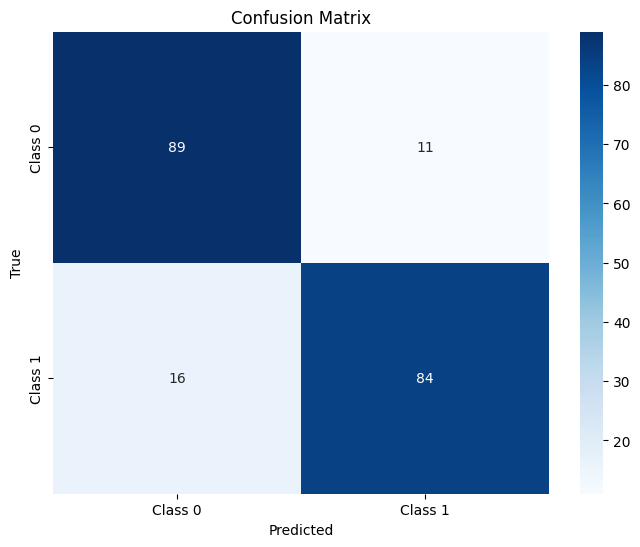

In [ ]:
#PERCOBAAN 1 (LAPORAN)
# Calculate and print confusion matrix
conf_matrix = confusion_matrix(y_true, y_pred_labels)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.savefig('Confusion Matrix 1.png')
plt.show()

In [ ]:
#PERCOBAAN 1 (LAPORAN)
# Calculate and print classification report
class_report = classification_report(y_true, y_pred_labels, target_names=['Class 0', 'Class 1'])
print(class_report)

# Calculate and print AUC
roc_auc = roc_auc_score(y_true, y_pred_labels)
print(f'AUC: {roc_auc}')

# Calculate and print F1 score
f1 = f1_score(y_true, y_pred_labels)
print(f'F1 Score: {f1}')

# Plot ROC curve
fpr, tpr, _ = roc_curve(y_true, y_pred_labels)
roc_auc = auc(fpr, tpr)

              precision    recall  f1-score   support

     Class 0       0.85      0.89      0.87       100
     Class 1       0.88      0.84      0.86       100

    accuracy                           0.86       200
   macro avg       0.87      0.86      0.86       200
weighted avg       0.87      0.86      0.86       200

AUC: 0.865
F1 Score: 0.8615384615384616


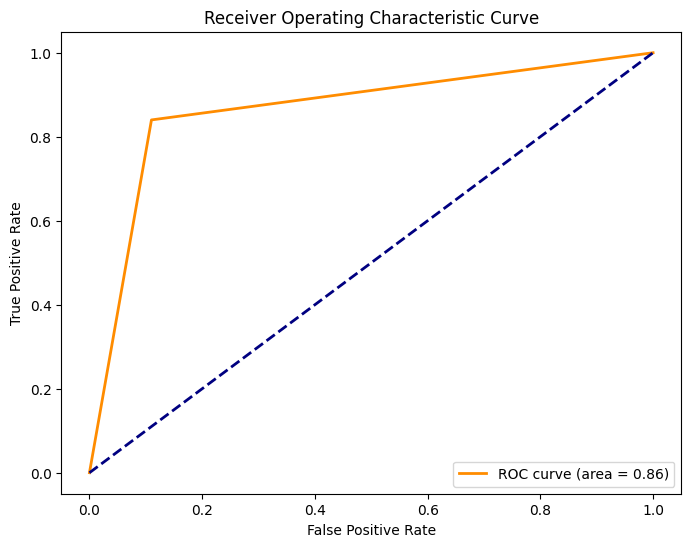

In [ ]:
#PERCOBAAN 1 (LAPORAN)
plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic Curve')
plt.legend(loc='lower right')
plt.savefig('ROC 1.png')
plt.show()

In [ ]:
#PERCOBAAN 1 (LAPORAN)
# Plotting accuracy
plt.figure(figsize=(20,10))
plt.subplot(1, 2, 1)
plt.suptitle('Optimizer : Adam', fontsize=10)
plt.ylabel('loss', fontsize=16)
plt.plot(emotion_model_info.history['loss'], label='Training Loss')
plt.plot(emotion_model_info.history['val_loss'], label='Validation Loss')
plt.legend(loc='upper right')

plt.subplot(1, 2, 2)
plt.ylabel('Accuracy', fontsize=16)
plt.plot(emotion_model_info.history['accuracy'], label='Training Accuracy')
plt.plot(emotion_model_info.history['val_accuracy'], label='Validation Accuracy')
plt.legend(loc='lower right')
plt.savefig('Accuracy 1.png')
plt.show()